# **Simple Linear Regression Model:- Predicting sunday newspaper circulation based on weekly newspaper circulation**

**Design and implement simple linear regression model to predict sunday newspaper <br> circulation based on daily newspaper circulation<br>
Predict sunday paper circulation for 200,300,and 500 daily circulation<br>Evaluate model with R-square and adjusted R-Square**

## **Import Data Set**

In [1]:
import pandas as pd
df_news = pd.read_csv(r"C:\Users\LENOVO\Downloads\NewspaperData.csv")
df_news.head(10)

,Newspaper,daily,sunday
0,Baltimore Sun,391.952,488.506
1,Boston Globe,516.981,798.298
2,Boston Herald,355.628,235.084
3,Charlotte Observer,238.555,299.451
4,Chicago Sun Times,537.780,559.093
5,Chicago Tribune,733.775,1133.249
6,Cincinnati Enquirer,198.832,348.744
7,Denver Post,252.624,417.779
8,Des Moines Register,206.204,344.522
9,Hartford Courant,231.177,323.084


## **Correlation**

In [2]:
df_news.select_dtypes(include="number").corr()

,daily,sunday
daily,1.000000,0.958154
sunday,0.958154,1.000000


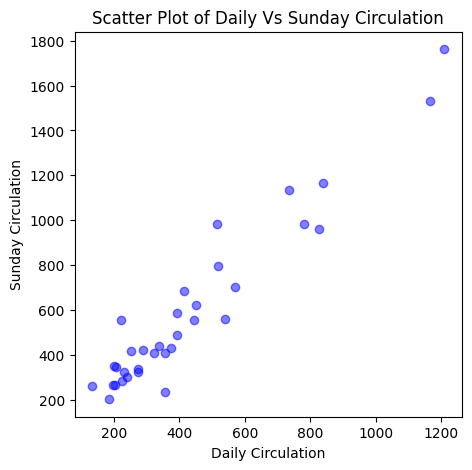

In [3]:
import matplotlib.pyplot as plt


# Extracting daily and sunday circulation data
daily_data = df_news['daily']
sunday_data = df_news['sunday']

# Plotting scatter plot 
plt.figure(figsize=(5,5))
plt.scatter(daily_data,sunday_data,color ='blue',alpha=0.5)
plt.title("Scatter Plot of Daily Vs Sunday Circulation")
plt.xlabel("Daily Circulation")
plt.ylabel("Sunday Circulation")
plt.show()

# **Inferance:**
There is a stronge correlation between sunday and daily circulation

### **Fitting a linear Regression Model**

In [4]:
import statsmodels.formula.api as smf
model = smf.ols('sunday~daily',data=df_news).fit()

In [5]:
# Regression equation has built sucessfully

In [6]:
model.params

Intercept    13.835630
daily         1.339715
dtype: float64

In [7]:
#t and p-Values
print(f'model t-values:\n{model.tvalues}\n-------\nmodel p-values: \n{model.pvalues}')

model t-values:
Intercept     0.386427
daily        18.934840
dtype: float64
-------
model p-values: 
Intercept    7.017382e-01
daily        6.016802e-19
dtype: float64


## **To summerise if p value for any feature (variable) is <0.05,<br>that variable is inportant , and suggest not drop from data set**

In [8]:
# Cofficients
model.params

Intercept    13.835630
daily         1.339715
dtype: float64

In [9]:
# to predict for 200 daily circulation
(1.339715*200)+13.835630

281.77862999999996

In [10]:
(1.339715*300)+13.835630 # for 300 newspaper

415.75012999999996

In [11]:
(1.339715*500)+13.835630 # for 500 newspaper

683.69313

In [12]:
# R squared values 
(model.rsquared,model.rsquared_adj)

(np.float64(0.9180596895873295), np.float64(0.9154990548869336))

## **R-squared**
R^2 tells us how well the model fits the data. close to 1=better fit.<br>
Example: If R^2 = 0.91 the model explains 91% of the variation in y<br>
But R^2 has a quirk - it always increases when we add mor features, even useless ones!

## **Adjusted R-squared deals with this issue.**
Adjusted r^2 fixes this quirk by penalizing extra features that don't help.<br>
Rule of thumb : if a feature doestn't imporove the model enough ,Adjusted R^2 decreases.<br>
Watch how Adjusted R^2 Changes when we add/remove features later!

## **Predict new data points**

In [15]:
# predict for 200 and 300 daily circulation
newdata = pd.Series([200,300,500])
newdata

0    200
1    300
2    500
dtype: int64

In [17]:
data_pred= pd.DataFrame(newdata,columns=['daily'])

In [18]:
data_pred

,daily
0,200
1,300
2,500


In [19]:
model.predict(data_pred)

0    281.778581
1    415.750057
2    683.693009
dtype: float64

In [20]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 sunday   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.915
Method:                 Least Squares   F-statistic:                     358.5
Date:                Mon, 05 Jan 2026   Prob (F-statistic):           6.02e-19
Time:                        12:08:33   Log-Likelihood:                -206.85
No. Observations:                  34   AIC:                             417.7
Df Residuals:                      32   BIC:                             420.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     13.8356     35.804      0.386      0.702     -59.095      86.766
daily          1.3397      0.071     18.935      0.000       1.196       1.484
==============================================================================
Omnibus:                        3.297   Durbin-Watson:                   2.059
Prob(Omnibus):                  0.192   Jarque-Bera (JB):                1.990
Skew:                           0.396   Prob(JB):                        0.370
Kurtosis:                       3.882   Cond. No.                         965.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""